# Sample Selection — Discrete 2×2 GMM Estimation

Replaces the bivariate lognormal (SMM) with a **discrete joint distribution** of
individual hazards $(\lambda_i, \delta_i)$: two levels per hazard (High/Low), giving
4 worker types with free shares.

**Key advantage**: closed-form bin probabilities — no simulation needed.
The progression through bins is a mixture of pure-birth continuous-time Markov chains
with alternating exponential holding times.

| Type | $\lambda$ | $\delta$ | Interpretation |
|------|-----------|----------|----------------|
| HH   | High      | High     | "Fast cycler"  |
| HL   | High      | Low      | **Stable worker** (exits unstable quickly, stays in stable long) |
| LH   | Low       | High     | **Unstable worker** (stuck in unstable, exits stable quickly) |
| LL   | Low       | Low      | "Slow cycler"  |

**Parameters** (7): $\lambda_H, \lambda_L, \delta_H, \delta_L, \pi_{HH}, \pi_{HL}, \pi_{LH}$
($\pi_{LL} = 1 - \pi_{HH} - \pi_{HL} - \pi_{LH}$).

**Targets** (22): 5-bin spell-completion shares at 4 time horizons (20) + mean hazard rates (2).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.optimize import differential_evolution, minimize

np.random.seed(42)

plt.rcParams['figure.dpi'] = 120
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

In [2]:
# ---- Configuration ----

VERSION = "v21"       # Spell data version
END_YEAR = 2021       # Last year of observation

YEARS = [2011, 2005, 1999, 1992]
HORIZONS = [(END_YEAR - y) * 12 for y in YEARS]     # Horizon in months

P_START_U = 0.4       # Fraction starting in unstable spell

TYPE_LABELS = ['HH', 'HL', 'LH', 'LL']
TYPE_NAMES  = ['Fast cycler', 'Stable worker', 'Unstable worker', 'Slow cycler']

print("Horizons (months):", HORIZONS)
print("Horizons (years): ", [h/12 for h in HORIZONS])

Horizons (months): [120, 192, 264, 348]
Horizons (years):  [10.0, 16.0, 22.0, 29.0]


## Part 0: Data

In [3]:
# Load unstable (T) and stable (P) spell data for each window
data_T, data_P = {}, {}
for year in YEARS:
    data_T[year] = pd.read_csv(f'./data/raw/spain/duration/dur_{year}_T_1obs_unfin_{VERSION}.csv')
    data_P[year] = pd.read_csv(f'./data/raw/spain/duration/dur_{year}_P_1obs_unfin_{VERSION}_strict.csv')
    data_T[year]['months'] = data_T[year]['days'] / 30
    data_P[year]['months'] = data_P[year]['days'] / 30

data_all_T = data_T[YEARS[-1]]
data_all_P = data_P[YEARS[-1]]
print(f'Unstable spells ({YEARS[-1]} window): {len(data_all_T):,} obs')
print(f'Stable spells   ({YEARS[-1]} window): {len(data_all_P):,} obs')

Unstable spells (1992 window): 513,278 obs
Stable spells   (1992 window): 565,716 obs


In [4]:
# ---- P(start in unstable) by window ----
# For each window year, determine each individual's first spell type:
#   - only in data_T: first spell is unstable
#   - only in data_P: first spell is stable
#   - in both:        whichever has the lower jobcount came first

p_start_u_by_year = {}
for year in YEARS:
    jc_T = data_T[year].groupby('id')['jobcount'].min().rename('jc_T')
    jc_P = data_P[year].groupby('id')['jobcount'].min().rename('jc_P')
    merged = jc_T.to_frame().join(jc_P, how='outer')
    starts_T = (
        merged['jc_P'].isna() |
        (merged['jc_T'].notna() & (merged['jc_T'] < merged['jc_P']))
    )
    p_start_u_by_year[year] = starts_T.mean()

print('P(start in unstable) by window:')
for year in YEARS:
    print(f'  {year} window ({END_YEAR - year:2d} yrs):  {p_start_u_by_year[year]:.4f}')

P_START_U_VEC = [p_start_u_by_year[y] for y in YEARS]
print(f'\nFixed value used so far: P_START_U = {P_START_U}')

P(start in unstable) by window:
  2011 window (10 yrs):  0.3285
  2005 window (16 yrs):  0.3317
  1999 window (22 yrs):  0.3826
  1992 window (29 yrs):  0.3768

Fixed value used so far: P_START_U = 0.4


In [5]:
# MLE for censored exponential: lambda_hat = n_completed / sum(all durations)
def censored_exp_mle(df):
    n_completed = (df['unfin'] == 0).sum()
    total_duration = df['months'].sum()
    return n_completed / total_duration, n_completed

lambda_hat, n_compl_T = censored_exp_mle(data_all_T)
delta_hat, n_compl_P  = censored_exp_mle(data_all_P)

print(f'lambda_hat (unstable): {lambda_hat:.5f}  ->  E[dur] = {1/lambda_hat:.1f} months  (n_completed={n_compl_T:,})')
print(f'delta_hat  (stable):   {delta_hat:.5f}  ->  E[dur] = {1/delta_hat:.1f} months  (n_completed={n_compl_P:,})')

lambda_hat (unstable): 0.01743  ->  E[dur] = 57.4 months  (n_completed=423,994)
delta_hat  (stable):   0.00813  ->  E[dur] = 123.0 months  (n_completed=363,549)


In [6]:
print(n_compl_T/len(data_all_T))
print(n_compl_P/len(data_all_P))

0.8260513795642906
0.6426351738328065


In [7]:
def parse_long_keytab(filepath):
    '''Parse a Stata _long keytab log into 5-bin shares and total N.

    Reads the Freq. column (exact counts) rather than Percent, which Stata
    rounds to 2 dp. That rounding is a systematic (not random) perturbation of
    the GMM targets, ~7% of one sampling SD. This matches how the Germany
    parser (parse_descriptives_log) builds its shares.
    '''
    counts = {}
    total_n = None
    with open(filepath, encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split('|')
            if len(parts) == 2:
                left = parts[0].strip()
                right_parts = parts[1].strip().split()
                if left == 'Total' and len(right_parts) >= 1:
                    total_n = int(right_parts[0].replace(',', ''))
                elif left in ['0', '.5', '1', '1.5', '2'] and len(right_parts) >= 1:
                    counts[float(left)] = float(right_parts[0].replace(',', ''))
    if total_n is None:
        raise ValueError(f"no Total row found in {filepath}")
    shares = np.array([counts[k] for k in [0.0, 0.5, 1.0, 1.5, 2.0]]) / total_n
    return shares, total_n

# NOTE: current logs may be from v20 Stata run. Regenerate with v21 for full consistency.
data_shares = np.zeros((len(YEARS), 5))
data_N = np.zeros(len(YEARS))
for i, year in enumerate(YEARS):
    filepath = f'./data/intermediate/spain/descriptive_stats/desstats_sple_keytab{year}_long.log'
    data_shares[i], data_N[i] = parse_long_keytab(filepath)

share_df = pd.DataFrame(data_shares, index=YEARS, columns=['0','0.5','1','1.5','2'])
share_df['N'] = data_N.astype(int)
print('Target moments (spell completion shares by window):\n')
share_df

Target moments (spell completion shares by window):



,0,0.5,1,1.5,2,N
2011,0.337958,0.214137,0.255909,0.069425,0.122571,566253
2005,0.265453,0.170749,0.276568,0.076215,0.211015,598464
1999,0.218931,0.150728,0.290977,0.075338,0.264026,625836
1992,0.205464,0.134493,0.265896,0.068705,0.325442,663426


## Part 1: Analytical Model — Closed-Form Bin Probabilities

A worker of type $(j,k)$ has hazards $\lambda_j$ (unstable) and $\delta_k$ (stable).
Spell durations are exponential. The worker's career is a **pure-birth CTMC** that
alternates between unstable and stable states.

At horizon $T$, the worker's state determines their bin:

**U-starter** (prob $p_U$): $U_1(\lambda) \to S_1(\delta) \to U_2(\lambda)$

| Bin | Condition |
|-----|-----------|
| 0.5 | $U_1 > T$ |
| 1   | $U_1 + S_1 > T$ but $U_1 < T$ |
| 1.5 | $U_1 + S_1 + U_2 > T$ but $U_1 + S_1 < T$ |
| 2   | $U_1 + S_1 + U_2 < T$ |

**S-starter** (prob $1 - p_U$): $S_0(\delta) \to U_1(\lambda) \to S_1(\delta) \to U_2(\lambda)$

| Bin | Condition |
|-----|-----------|
| 0   | $S_0 > T$ |
| 0.5 | $S_0 + U_1 > T$ but $S_0 < T$ |
| 1   | first three spells' sum $> T$ but first two $< T$ |
| 1.5 | all four spells' sum $> T$ but first three $< T$ |
| 2   | $S_0 + U_1 + S_1 + U_2 < T$ |

The bin probabilities reduce to **survival functions of sums of exponentials**,
which have exact closed-form expressions. Let $d = a - b$:

$$\Psi_2(T;\, a,b) = \frac{a\,e^{-bT} - b\,e^{-aT}}{d}$$

$$\Psi_3(T;\, a,b) = \frac{a^2\,e^{-bT} \;-\; b\,(2a{-}b + adT)\,e^{-aT}}{d^2}$$

$$\Psi_4(T;\, a,b) = \frac{b^2(3a{-}b + adT)\,e^{-aT} \;+\; a^2(a{-}3b + bdT)\,e^{-bT}}{d^3}$$

where $\Psi_n$ is $P(\text{sum of } n \text{ exponentials} > T)$, and in $\Psi_3$ rate $a$ has multiplicity 2.

In [8]:
# ---- Survival functions for sums of independent exponentials ----
#
# surv_11(T, a, b)  = P(Exp(a) + Exp(b) > T)
# surv_21(T, a, b)  = P(2*Exp(a) + Exp(b) > T)   [a has multiplicity 2]
# surv_22(T, a, b)  = P(2*Exp(a) + 2*Exp(b) > T)  [symmetric in a, b]
#
# Derived from the forward Kolmogorov equations of the underlying CTMC.

def _surv_11(T, a, b):
    """P(Exp(a) + Exp(b) > T)."""
    d = a - b
    if abs(d) < 1e-10 * max(a, b, 1e-20):
        r = 0.5 * (a + b)
        return (1 + r * T) * np.exp(-r * T)
    e_a, e_b = np.exp(-a * T), np.exp(-b * T)
    return (a * e_b - b * e_a) / d


def _surv_21(T, a, b):
    """P(2*Exp(a) + Exp(b) > T).  a has multiplicity 2."""
    d = a - b
    if abs(d) < 1e-10 * max(a, b, 1e-20):
        r = 0.5 * (a + b)
        rT = r * T
        return (1 + rT + 0.5 * rT**2) * np.exp(-r * T)
    e_a, e_b = np.exp(-a * T), np.exp(-b * T)
    d2 = d * d
    return (a**2 * e_b - b * (2*a - b + a*d*T) * e_a) / d2


def _surv_22(T, a, b):
    """P(2*Exp(a) + 2*Exp(b) > T).  Symmetric in a, b."""
    d = a - b
    if abs(d) < 1e-10 * max(a, b, 1e-20):
        r = 0.5 * (a + b)
        rT = r * T
        return (1 + rT + 0.5*rT**2 + rT**3/6.0) * np.exp(-r * T)
    e_a, e_b = np.exp(-a * T), np.exp(-b * T)
    d3 = d**3
    dT = d * T
    return (b**2 * (3*a - b + a*dT) * e_a +
            a**2 * (a - 3*b + b*dT) * e_b) / d3


print('Survival functions defined.')
# Unit test: all must equal 1 at T=0
for fn, args in [(_surv_11, (0, 0.05, 0.02)),
                 (_surv_21, (0, 0.05, 0.02)),
                 (_surv_22, (0, 0.05, 0.02)),
                 (_surv_21, (0, 0.02, 0.05))]:
    assert abs(fn(*args) - 1.0) < 1e-12, f'{fn.__name__} failed at T=0'
print('T=0 unit tests passed.')

Survival functions defined.
T=0 unit tests passed.


In [9]:
def _censored_mle_model(rates, shares, W):
    """Model-implied censored MLE under uniform entry over [0, W].

    Matches what censored_exp_mle() computes from the data when each worker
    contributes only their first spell and entry is approximately uniform
    over the observation window.

    For each type k the censoring time C ~ Uniform(0, W) gives:
        P(T < C)     = 1 - (1 - exp(-lambda_k * W)) / (lambda_k * W)
        E[min(T, C)] = P(T < C) / lambda_k

    The mixture-implied censored MLE is then:
        sum_k pi_k * P(T < C | k)  /  sum_k pi_k * E[min(T,C) | k]
    """
    rates = np.asarray(rates, dtype=float)
    shares = np.asarray(shares, dtype=float)
    lW = rates * W
    completions = 1.0 - (1.0 - np.exp(-lW)) / lW   # P(complete | type k)
    weights = shares * completions                    # pi_k * P(complete | k)
    return weights.sum() / (weights / rates).sum()


def bin_probs_single(lam, delta, T, p_start_u=0.4):
    """Closed-form 5-bin probabilities for a single type (lam, delta) at horizon T.
    Returns array [P(bin=0), P(bin=0.5), P(bin=1), P(bin=1.5), P(bin=2)].
    """
    p_s = 1.0 - p_start_u

    # U-starter milestones (rate sequence: lam, delta, lam)
    psi_u1 = np.exp(-lam * T)
    psi_u2 = _surv_11(T, lam, delta)
    psi_u3 = _surv_21(T, lam, delta)       # lam has multiplicity 2

    # S-starter milestones (rate sequence: delta, lam, delta, lam)
    psi_s1 = np.exp(-delta * T)
    psi_s2 = _surv_11(T, delta, lam)       # symmetric with psi_u2
    psi_s3 = _surv_21(T, delta, lam)       # delta has multiplicity 2
    psi_s4 = _surv_22(T, delta, lam)       # symmetric

    # U-starter bins
    b0_u  = 0.0
    b05_u = psi_u1
    b1_u  = psi_u2 - psi_u1
    b15_u = psi_u3 - psi_u2
    b2_u  = 1.0 - psi_u3

    # S-starter bins
    b0_s  = psi_s1
    b05_s = psi_s2 - psi_s1
    b1_s  = psi_s3 - psi_s2
    b15_s = psi_s4 - psi_s3
    b2_s  = 1.0 - psi_s4

    return np.array([
        p_start_u * b0_u  + p_s * b0_s,
        p_start_u * b05_u + p_s * b05_s,
        p_start_u * b1_u  + p_s * b1_s,
        p_start_u * b15_u + p_s * b15_s,
        p_start_u * b2_u  + p_s * b2_s,
    ])


def model_moms_discrete(lam_H, lam_L, delta_H, delta_L,
                        pi_HH, pi_HL, pi_LH, p_start_vec=None,
                        horizons=None, W=None):
    """Model-implied moments for the discrete 2x2 mixture.
    Returns: (moms, mean_lam, mean_del)
        moms     : ndarray (n_horizons, 5) bin shares
        mean_lam : model-implied censored MLE for lambda (matches data's censored_exp_mle)
        mean_del : model-implied censored MLE for delta
    W is the observation window in months (defaults to max(HORIZONS)).
    """
    if horizons is None:
        horizons = HORIZONS
    if W is None:
        W = max(HORIZONS)
    if p_start_vec is None:
        p_start_vec = P_START_U_VEC

    pi_LL = 1.0 - pi_HH - pi_HL - pi_LH
    types = [
        (lam_H, delta_H, pi_HH),
        (lam_H, delta_L, pi_HL),
        (lam_L, delta_H, pi_LH),
        (lam_L, delta_L, pi_LL),
    ]

    n_h = len(horizons)
    moms = np.zeros((n_h, 5))
    for i, T in enumerate(horizons):
        p_start_u = p_start_vec[i]
        for lam, delta, pi in types:
            moms[i] += pi * bin_probs_single(lam, delta, T, p_start_u)

    # share_lam_H = pi_HH + pi_HL
    # share_lam_L = pi_LH + pi_LL
    # share_del_H = pi_HH + pi_LH
    # share_del_L = pi_HL + pi_LL

    # mean_lam = _censored_mle_model(
    #     np.array([lam_H, lam_L]),
    #     np.array([share_lam_H, share_lam_L]),
    #     W)
    # mean_del = _censored_mle_model(
    #     np.array([delta_H, delta_L]),
    #     np.array([share_del_H, share_del_L]),
    #     W)

    return moms #, mean_lam, mean_del 


print('Model functions defined.')


Model functions defined.


In [10]:
# ---- Sanity check: analytical vs Monte Carlo simulation ----

lam_test, delta_test, T_test = 0.05, 0.02, 120
N_sim = 500_000

bins_analytical = bin_probs_single(lam_test, delta_test, T_test, p_start_u=P_START_U_VEC[-1])

np.random.seed(42)
is_u = np.random.random(N_sim) < P_START_U_VEC[-1]
u1 = np.random.exponential(1/lam_test, N_sim)
s1 = np.random.exponential(1/delta_test, N_sim)
u2 = np.random.exponential(1/lam_test, N_sim)
s0 = np.random.exponential(1/delta_test, N_sim)

res00 = np.where(is_u, 0.0, s0)
res0  = np.where(is_u, u1, s0 + u1)
res1  = np.where(is_u, u1 + s1, s0 + u1 + s1)
res2  = np.where(is_u, u1 + s1 + u2, s0 + u1 + s1 + u2)

b0  = res00 >= T_test
b05 = (res00 < T_test) & (res0 >= T_test)
b1  = (res0 < T_test) & (res1 >= T_test)
b15 = (res1 < T_test) & (res2 >= T_test)
b2  = res2 < T_test
bins_sim = np.array([b0.mean(), b05.mean(), b1.mean(), b15.mean(), b2.mean()])

print(f'Sanity check: lam={lam_test}, delta={delta_test}, T={T_test} months, N_sim={N_sim:,}')
print(f'{"Bin":>5s}  {"Analytical":>10s}  {"Simulated":>10s}  {"Diff":>10s}')
print('-' * 42)
for j, bl in enumerate(['0', '0.5', '1', '1.5', '2']):
    print(f'{bl:>5s}  {bins_analytical[j]:10.5f}  {bins_sim[j]:10.5f}  {bins_sim[j]-bins_analytical[j]:+10.5f}')
print(f'{"Sum":>5s}  {bins_analytical.sum():10.5f}  {bins_sim.sum():10.5f}')
assert np.allclose(bins_analytical, bins_sim, atol=0.003), 'Analytical vs MC mismatch!'
print('\nAnalytical formulas match simulation.')

Sanity check: lam=0.05, delta=0.02, T=120 months, N_sim=500,000
  Bin  Analytical   Simulated        Diff
------------------------------------------
    0     0.05654     0.05653    -0.00001
  0.5     0.03760     0.03797    +0.00038
    1     0.22046     0.21982    -0.00064
  1.5     0.10662     0.10601    -0.00061
    2     0.57879     0.57967    +0.00088
  Sum     1.00000     1.00000

Analytical formulas match simulation.


## Part 2: GMM Estimation

Since the model moments are analytical, this is exact **GMM** (no simulation noise).

**Reparameterization** (unconstrained $\theta \in \mathbb{R}^7$):
- $\theta_0 = \log \lambda_L$, $\theta_1 = \log(\lambda_H / \lambda_L)$ ensures $\lambda_H > \lambda_L > 0$
- $\theta_2 = \log \delta_L$, $\theta_3 = \log(\delta_H / \delta_L)$ ensures $\delta_H > \delta_L > 0$
- $\theta_{4:7}$ = logits $\to$ softmax gives $(\pi_{HH}, \pi_{HL}, \pi_{LH}, \pi_{LL})$ on the simplex

**Optimizer**: Differential evolution (global search) with local polish.

In [11]:
# ---- Weighting matrix ----
def build_weight_matrix(data_shares, data_N): # lambda_hat, delta_hat,n_compl_T, n_compl_P):
    """Diagonal inverse-variance weighting for 22 moments:
    20 bin shares + 2 mean hazard rates."""
    n_h, n_bins = data_shares.shape
    # n_moms = n_h * n_bins + 2
    n_moms = n_h * n_bins
    W = np.zeros((n_moms, n_moms))
    for i in range(n_h):
        for j in range(n_bins):
            p = data_shares[i, j]
            idx = i * n_bins + j
            var_p = max(p * (1 - p) / data_N[i], 1e-12)
            W[idx, idx] = 1.0 / var_p
    # Mean hazard weights: 1/Var(lambda_hat) ~ n_completed / lambda^2
    # W[20, 20] = n_compl_T / lambda_hat**2
    # W[21, 21] = 1e7 #n_compl_P / delta_hat**2
    return W

W = build_weight_matrix(data_shares, data_N) #, lambda_hat, delta_hat,n_compl_T, n_compl_P)
print(f'Weighting matrix: {W.shape[0]} x {W.shape[1]}')
print(f'  Bin share weights range: {W.diagonal()[:20].min():.0f} - {W.diagonal()[:20].max():.0f}')
# print(f'  Mean lambda weight: {W[20,20]:.0f}')
# print(f'  Mean delta  weight: {W[21,21]:.0f}')

Weighting matrix: 20 x 20
  Bin share weights range: 2530824 - 10368456


In [12]:
def theta_to_params(theta):
    """Convert unconstrained theta (R^7) to model parameters."""
    lam_L   = np.exp(theta[0])
    lam_H   = lam_L * np.exp(theta[1])
    delta_L = np.exp(theta[2])
    delta_H = delta_L * np.exp(theta[3])
    logits = np.array([theta[4], theta[5], theta[6], 0.0])
    logits -= logits.max()
    exp_l = np.exp(logits)
    shares = exp_l / exp_l.sum()
    pi_HH, pi_HL, pi_LH, pi_LL = shares
    return lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, pi_LL


# Build data target vector: 20 bin shares + 2 hazard rates
# data_moms_full = np.concatenate([data_shares.ravel(), [lambda_hat, delta_hat]])
data_moms_full = data_shares.ravel()


def objective(theta, data_target, W, horizons, p_start_vec):
    """Weighted GMM objective -- fully analytical, no simulation."""
    lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, pi_LL = theta_to_params(theta)
    moms = model_moms_discrete(
        lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, horizons=horizons, p_start_vec=p_start_vec)
    model_full = moms.ravel()
    diff = model_full - data_target
    return float(diff @ W @ diff)


print('Objective function defined.')

Objective function defined.


In [13]:
# ---- Differential Evolution ----

bounds = [
    (-8.0, -1),    # log(lam_L)
    ( 0.8,  8.0),    # log(lam_H / lam_L)
    (-9.0, -1.0),    # log(delta_L)
    ( 0.8,  3.5),    # log(delta_H / delta_L)
    (-4.0,  4.0),    # logit pi_HH
    (-4.0,  4.0),    # logit pi_HL
    (-4.0,  4.0),    # logit pi_LH
]

print('Running differential evolution...\n')

result = differential_evolution(
    objective, bounds=bounds,
    args=(data_moms_full, W, HORIZONS, P_START_U_VEC),
    seed=42, maxiter=500, tol=1e-10,
    polish=True, popsize=25, mutation=(0.5, 1.5), recombination=0.9,
)

lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH, pi_LL = theta_to_params(result.x)

print(f'Converged: {result.success}   nfev: {result.nfev}')
print(f'Objective: {result.fun:.2f}\n')
print(f'  lam_H   = {lam_H:.5f}   (E[unstable dur] = {1/lam_H:.1f} months)')
print(f'  lam_L   = {lam_L:.5f}   (E[unstable dur] = {1/lam_L:.1f} months)')
print(f'  delta_H = {delta_H:.5f}   (E[stable dur]   = {1/delta_H:.1f} months)')
print(f'  delta_L = {delta_L:.5f}   (E[stable dur]   = {1/delta_L:.1f} months)')
print(f'\nType shares:')
print(f'  pi_HH (fast cycler)      = {pi_HH:.4f}')
print(f'  pi_HL (stable worker)    = {pi_HL:.4f}')
print(f'  pi_LH (unstable worker)  = {pi_LH:.4f}')
print(f'  pi_LL (slow cycler)      = {pi_LL:.4f}')
print(f'  Sum = {pi_HH+pi_HL+pi_LH+pi_LL:.6f}')

Running differential evolution...

Converged: True   nfev: 56199
Objective: 5988.33

  lam_H   = 0.02573   (E[unstable dur] = 38.9 months)
  lam_L   = 0.00150   (E[unstable dur] = 668.6 months)
  delta_H = 0.04098   (E[stable dur]   = 24.4 months)
  delta_L = 0.00225   (E[stable dur]   = 444.9 months)

Type shares:
  pi_HH (fast cycler)      = 0.1564
  pi_HL (stable worker)    = 0.6516
  pi_LH (unstable worker)  = 0.1801
  pi_LL (slow cycler)      = 0.0119
  Sum = 1.000000


Previous results - targeting "crude" average hazards

 --- Hazard rates ---
 
   lambda_H = 0.01950  (mean unstable dur = 51.3 months)
   
   lambda_L = 0.00141  (mean unstable dur = 707.1 months)
   
   delta_H  = 0.25700  (mean stable dur   = 3.9 months)
   
   delta_L  = 0.00240  (mean stable dur   = 416.9 months)

In [14]:
# ---- Type grid: rates + shares for the four types ----
# Defined right after the estimation so every downstream cell can use them.
# (Previously these were only defined near the end, after the cells that use
#  them, which breaks a top-to-bottom Run All.)
type_rates       = [(lam_H, delta_H), (lam_H, delta_L),
                    (lam_L, delta_H), (lam_L, delta_L)]
type_shares_list = [pi_HH, pi_HL, pi_LH, pi_LL]
colors_4         = ['#e74c3c', '#3498db', '#f39c12', '#2ecc71']

## Part 3: Results

In [15]:
# ---- Model vs Data: bin shares ----

best_moms= model_moms_discrete(
    lam_H, lam_L, delta_H, delta_L, pi_HH, pi_HL, pi_LH,
    horizons=HORIZONS, p_start_vec=P_START_U_VEC)

share_lam_H = pi_HH + pi_HL
share_lam_L = pi_LH + pi_LL
share_del_H = pi_HH + pi_LH
share_del_L = pi_HL + pi_LL

WW = max(HORIZONS)

best_mean_lam = _censored_mle_model(
    np.array([lam_H, lam_L]),
    np.array([share_lam_H, share_lam_L]),
    WW)
best_mean_del = _censored_mle_model(
    np.array([delta_H, delta_L]),
    np.array([share_del_H, share_del_L]),
    WW)

print('Model vs Data moments:\n')
print(f'{"Year":>6s}  {"Bin":>4s}  {"Data":>8s}  {"Model":>8s}  {"Diff":>8s}')
print('-' * 44)
bin_labels = ['0', '0.5', '1', '1.5', '2']
for i, year in enumerate(YEARS):
    for j, bl in enumerate(bin_labels):
        d, m = data_shares[i, j], best_moms[i, j]
        print(f'{year:>6d}  {bl:>4s}  {d:8.4f}  {m:8.4f}  {m-d:+8.4f}')
    print()

print('Mean hazard rates:')
print(f'  lambda: data={lambda_hat:.5f}, model={best_mean_lam:.5f}, diff={best_mean_lam-lambda_hat:+.5f}')
print(f'  delta:  data={delta_hat:.5f}, model={best_mean_del:.5f}, diff={best_mean_del-delta_hat:+.5f}')

Model vs Data moments:

  Year   Bin      Data     Model      Diff
--------------------------------------------
  2011     0    0.3380    0.3419   +0.0039
  2011   0.5    0.2141    0.2114   -0.0027
  2011     1    0.2559    0.2557   -0.0002
  2011   1.5    0.0694    0.0723   +0.0029
  2011     2    0.1226    0.1187   -0.0039

  2005     0    0.2655    0.2881   +0.0226
  2005   0.5    0.1707    0.1745   +0.0038
  2005     1    0.2766    0.2661   -0.0104
  2005   1.5    0.0762    0.0678   -0.0085
  2005     2    0.2110    0.2035   -0.0075

  1999     0    0.2189    0.2263   +0.0074
  1999   0.5    0.1507    0.1518   +0.0011
  1999     1    0.2910    0.2787   -0.0123
  1999   1.5    0.0753    0.0708   -0.0046
  1999     2    0.2640    0.2724   +0.0084

  1992     0    0.2055    0.1891   -0.0163
  1992   0.5    0.1345    0.1331   -0.0014
  1992     1    0.2659    0.2689   +0.0030
  1992   1.5    0.0687    0.0768   +0.0081
  1992     2    0.3254    0.3320   +0.0066

Mean hazard rates:
  lam

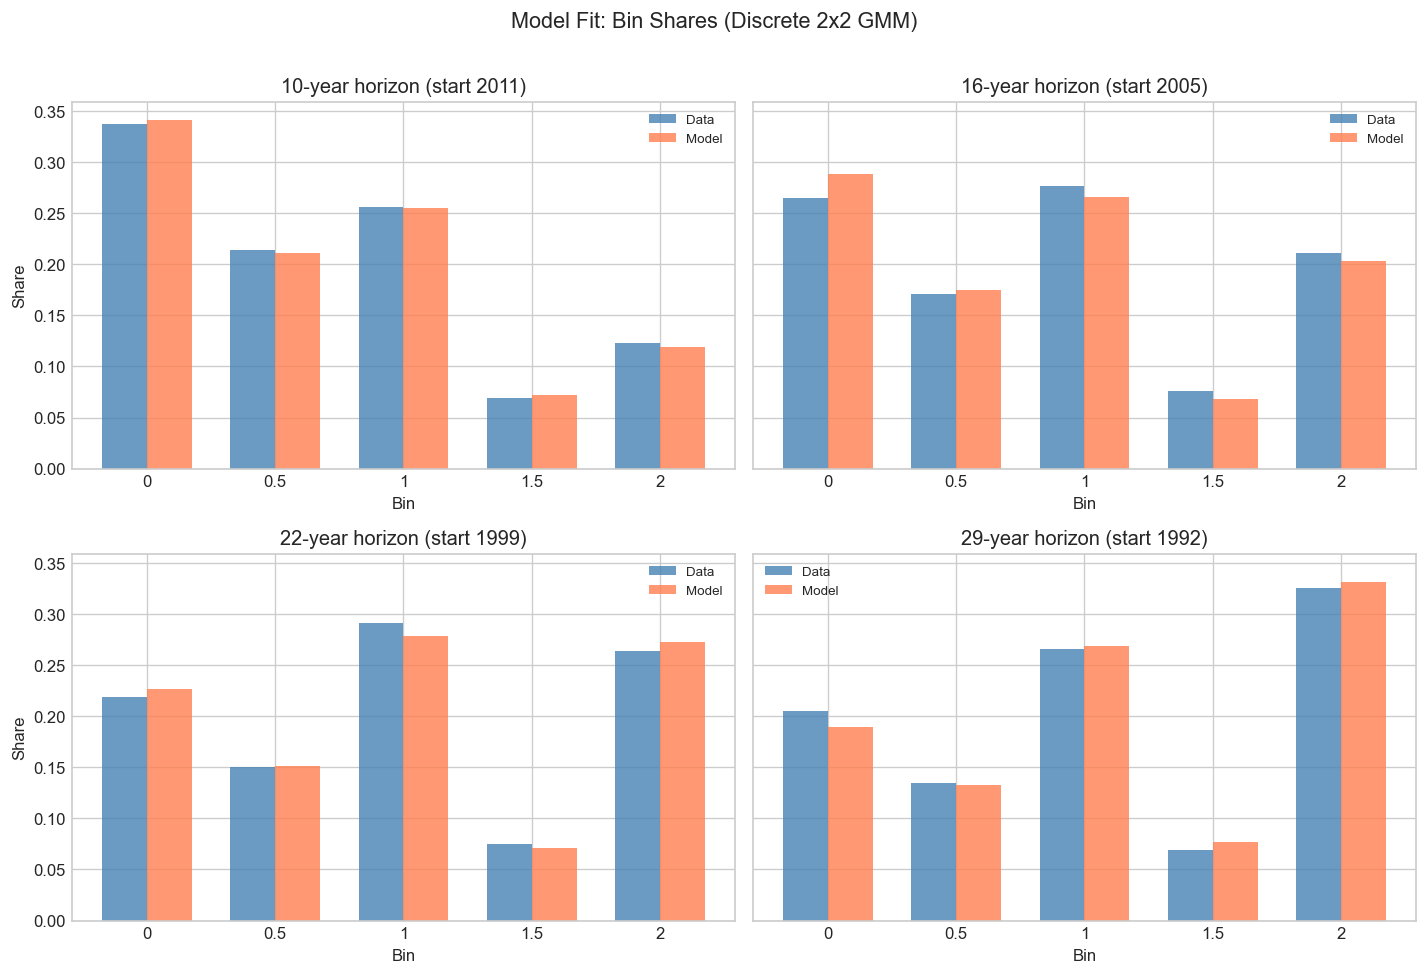

In [16]:
# ---- Model fit: grouped bar chart ----
os.makedirs('./sample_selection', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
bar_w = 0.35
x = np.arange(5)

for idx, (ax, year, T) in enumerate(zip(axes.flat, YEARS, HORIZONS)):
    ax.bar(x - bar_w/2, data_shares[idx], bar_w, label='Data', color='steelblue', alpha=0.8)
    ax.bar(x + bar_w/2, best_moms[idx], bar_w, label='Model', color='coral', alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels)
    ax.set_title(f'{T//12}-year horizon (start {year})')
    ax.set_xlabel('Bin')
    if idx % 2 == 0:
        ax.set_ylabel('Share')
    ax.legend(fontsize=8)

fig.suptitle('Model Fit: Bin Shares (Discrete 2x2 GMM)', fontsize=13, y=1.01)
fig.tight_layout()
# fig.savefig('./output/sample_selection/model_fit_discrete.png', bbox_inches='tight')
plt.show()

TYPE COMPOSITION BY BIN (collapsed)

 Horizon       Group       HH       HL       LH       LL    E[lam]    E[del]    Share
----------------------------------------------------------------------------------------
     10y  Population   0.1564   0.6516   0.1801   0.0119   0.02107   0.01528   1.0000
     10y  1 completed Spell   0.1575   0.7655   0.0745   0.0025   0.02386   0.01123   0.3280
     10y  2+ completed Spells   0.7652   0.2234   0.0113   0.0000   0.02545   0.03232   0.1187
          2+ spells/Pop    4.893x    0.343x    0.063x    0.004x   (HH: +389.3%, HL: -65.7%, LH: -93.7%, LL: -99.6%)
          2+ spells gap  E[lam]: 0.02545 vs 0.02107 (+20.8%)   E[del]: 0.03232 vs 0.01528 (+111.5%)
----------------------------------------------------------------------------------------
     16y  Population   0.1564   0.6516   0.1801   0.0119   0.02107   0.01528   1.0000
     16y  1 completed Spell   0.0523   0.8316   0.1121   0.0041   0.02291   0.00861   0.3339
     16y  2+ completed Spells 

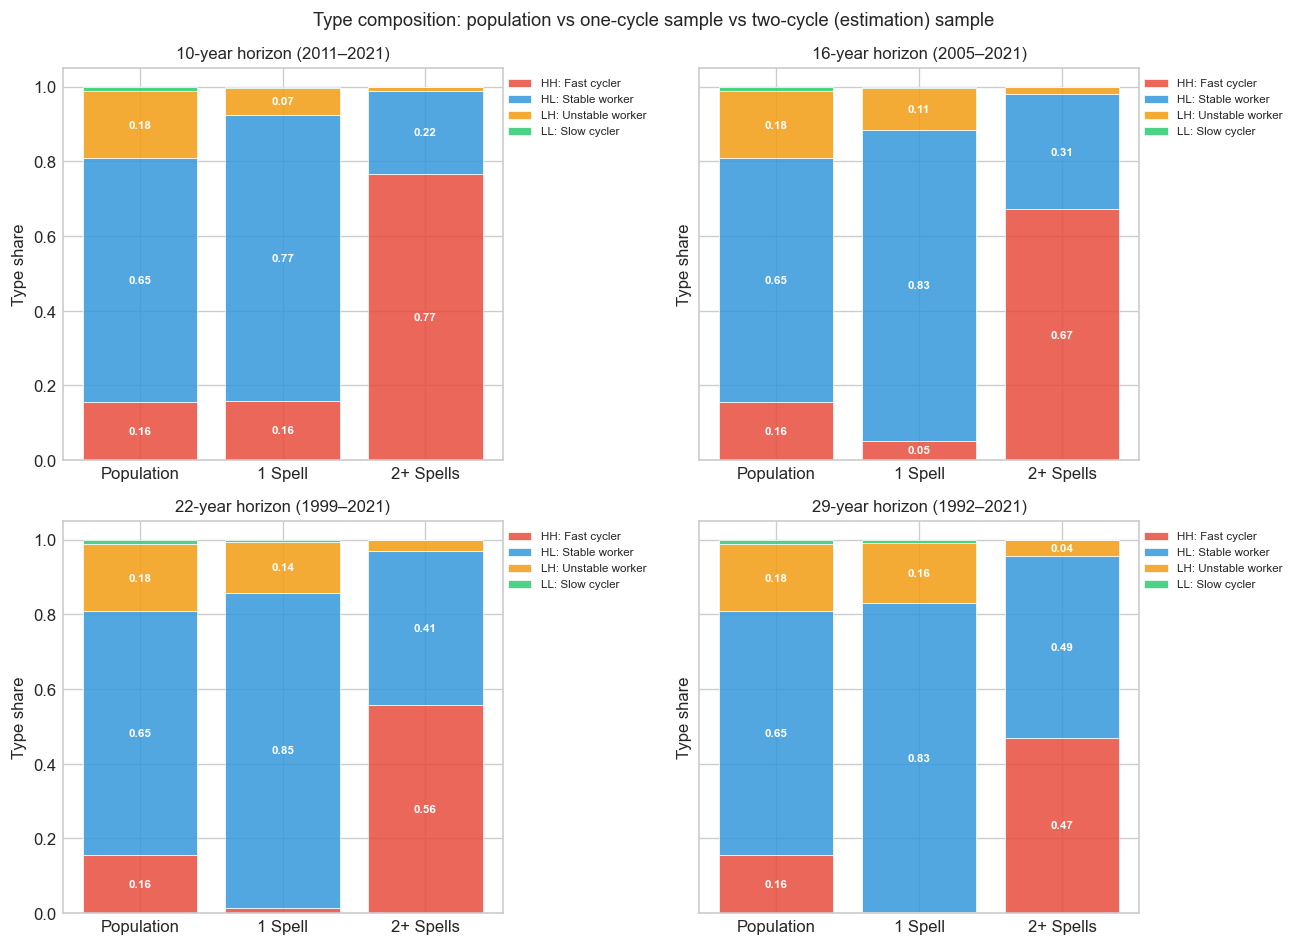

In [17]:
# ---- Paper figure: type composition collapsed to {Population, Bin 1, Bin 2} ----
#
# Bin 0   (no unstable spell started)    } discarded: worker never entered
# Bin 0.5 (one unfinished unstable)      } the unstable-spell sample
# Bin 1   (one complete cycle)           } collapsed to "Bin 1"
# Bin 1.5 (one complete + one unfinished)}
# Bin 2   (two complete cycles)          = estimation sample

type_rates_arr = np.array([(lam_H, delta_H), (lam_H, delta_L),
                            (lam_L, delta_H), (lam_L, delta_L)])
type_shares_arr = np.array([pi_HH, pi_HL, pi_LH, pi_LL])
lam_vals = np.array([lam_H, lam_H, lam_L, lam_L])
del_vals = np.array([delta_H, delta_L, delta_H, delta_L])

colors_4 = ['#e74c3c', '#3498db', '#f39c12', '#2ecc71']
col_labels = ['Population', '1 Spell', '2+ Spells']

def _collapsed_compositions(Ti,p_start_u_i):
    """For horizon Ti return (comp_pop, comp_bin1, comp_bin2), each shape (4,)."""
    per_type = np.array([
        bin_probs_single(lam, delta, Ti, p_start_u_i)
        for lam, delta in type_rates_arr
    ])                                          # shape (4, 5)
    bin1_type = per_type[:, 2] + per_type[:, 3]   # P(bin 1 or 1.5 | type k)
    bin2_type = per_type[:, 4]                     # P(bin 2 | type k)

    pop_bin1 = (type_shares_arr * bin1_type).sum()
    pop_bin2 = (type_shares_arr * bin2_type).sum()

    comp_pop  = type_shares_arr
    comp_bin1 = type_shares_arr * bin1_type / pop_bin1
    comp_bin2 = type_shares_arr * bin2_type / pop_bin2
    return comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2


# ---- Numerical summary for the paper ----
sep = '-' * 88
header = (f'{"Horizon":>8s}  {"Group":>10s}  '
          f'{"HH":>7s}  {"HL":>7s}  {"LH":>7s}  {"LL":>7s}  '
          f'{"E[lam]":>8s}  {"E[del]":>8s}  {"Share":>7s}')

print('TYPE COMPOSITION BY BIN (collapsed)\n')
print(header)
i=0
for Ti, year in zip(HORIZONS, YEARS):
    comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2 = _collapsed_compositions(Ti, P_START_U_VEC[i])
    pop_total = 1.0

    print(sep)
    rows = [
        ('Population', comp_pop,  pop_total),
        ('1 completed Spell',      comp_bin1, pop_bin1),
        ('2+ completed Spells',      comp_bin2, pop_bin2),
    ]
    for label, comp, share in rows:
        e_lam = (comp * lam_vals).sum()
        e_del = (comp * del_vals).sum()
        print(f'{Ti//12:>7d}y  {label:>10s}  ' +
              '  '.join(f'{c:7.4f}' for c in comp) +
              f'  {e_lam:8.5f}  {e_del:8.5f}  {share:7.4f}')

    # Over/under-representation: Bin 2 share relative to population
    ratio = comp_bin2 / comp_pop
    pct   = 100 * (ratio - 1)
    print(f'{"":>8s}  {"2+ spells/Pop":>10s}  ' +
          '  '.join(f'{r:7.3f}x' for r in ratio) +
          f'   ({", ".join(f"{TYPE_LABELS[t]}: {pct[t]:+.1f}%" for t in range(4))})')

    # Mean hazard gap: Bin 2 vs population
    e_lam_pop  = (comp_pop  * lam_vals).sum()
    e_lam_bin2 = (comp_bin2 * lam_vals).sum()
    e_del_pop  = (comp_pop  * del_vals).sum()
    e_del_bin2 = (comp_bin2 * del_vals).sum()
    print(f'{"":>8s}  {"2+ spells gap":>10s}  '
          f'E[lam]: {e_lam_bin2:.5f} vs {e_lam_pop:.5f} '
          f'({100*(e_lam_bin2/e_lam_pop - 1):+.1f}%)   '
          f'E[del]: {e_del_bin2:.5f} vs {e_del_pop:.5f} '
          f'({100*(e_del_bin2/e_del_pop - 1):+.1f}%)')
    i+=1

print(sep)


# ---- Figures ----
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
i = 0
for ax, Ti, year in zip(axes.flat, HORIZONS, YEARS):
    comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2 = _collapsed_compositions(Ti, P_START_U_VEC[i])

    bottom = np.zeros(3)
    for t in range(4):
        heights = np.array([comp_pop[t], comp_bin1[t], comp_bin2[t]])
        ax.bar(col_labels, heights, bottom=bottom,
               label=f'{TYPE_LABELS[t]}: {TYPE_NAMES[t]}',
               color=colors_4[t], alpha=0.85, edgecolor='white', linewidth=0.5)
        # Label inside bar if large enough
        for xi, (h, b) in enumerate(zip(heights, bottom)):
            if h > 0.04:
                ax.text(xi, b + h/2, f'{h:.2f}', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')
        bottom += heights
    i+=1
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Type share')
    ax.set_title(f'{Ti//12}-year horizon ({year}–{END_YEAR})', fontsize=10)
    ax.legend(fontsize=7, loc='upper right', bbox_to_anchor=(1.35, 1.0))

fig.suptitle(
    'Type composition: population vs one-cycle sample vs two-cycle (estimation) sample',
    fontsize=11)
fig.tight_layout()
fig.savefig('./output/sample_selection/type_composition_paper_discrete.png', bbox_inches='tight', dpi=150)
plt.show()


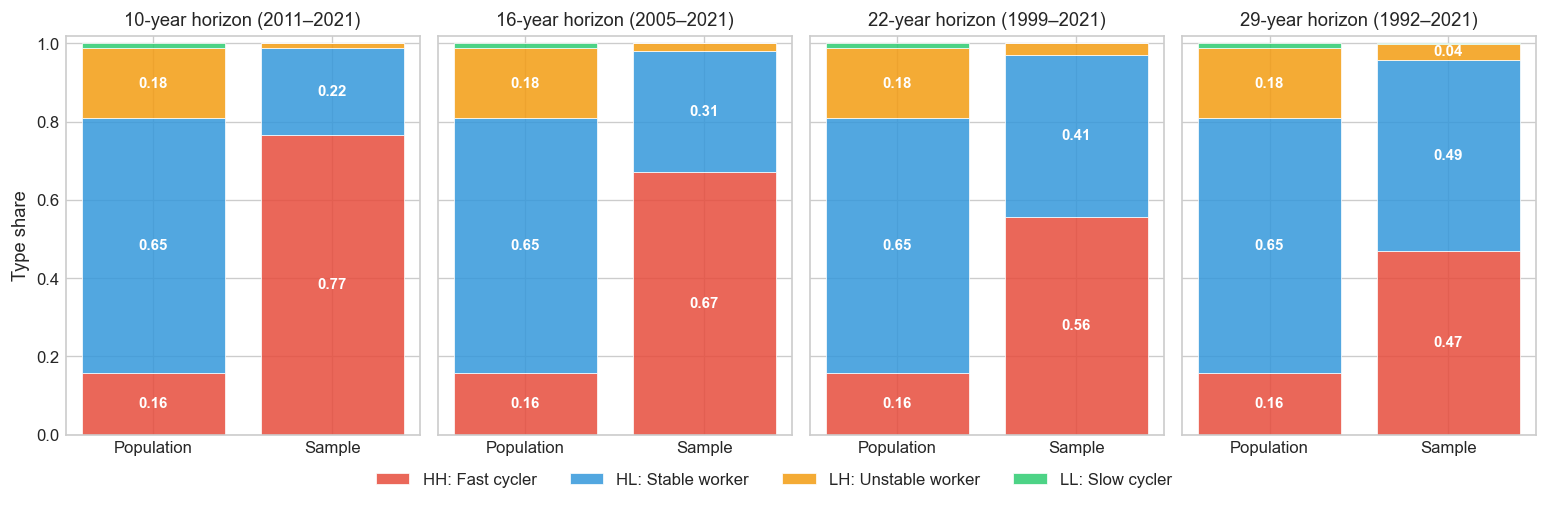

In [18]:
# ---- Figures ----
col_labels = ['Population', 'Sample']
fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharey=True)
i = 0
for ax, Ti, year in zip(axes.flat, HORIZONS, YEARS):
    comp_pop, comp_bin1, comp_bin2, pop_bin1, pop_bin2 = _collapsed_compositions(Ti, P_START_U_VEC[i])

    bottom = np.zeros(2)
    for t in range(4):
        heights = np.array([comp_pop[t], comp_bin2[t]])
        ax.bar(col_labels, heights, bottom=bottom,
                   label=f'{TYPE_LABELS[t]}: {TYPE_NAMES[t]}',
                   color=colors_4[t], alpha=0.85, edgecolor='white', linewidth=0.5)
        # Label inside bar if large enough
        for xi, (h, b) in enumerate(zip(heights, bottom)):
            if h > 0.04:
                ax.text(xi, b + h/2, f'{h:.2f}', ha='center', va='center',
                        fontsize=9, color='white', fontweight='bold')
        bottom += heights
    ax.set_ylim(0, 1.02)
    ax.set_title(f'{Ti//12}-year horizon ({year}–{END_YEAR})', fontsize=11)
    i += 1

axes[0].set_ylabel('Type share', fontsize=11)

# One shared legend below the panels (handles taken from the first axes)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=10,
           frameon=False, bbox_to_anchor=(0.5, -0.06))

fig.tight_layout()
fig.savefig('./output/sample_selection/type_composition_paper_simple.png',
            bbox_inches='tight', dpi=150)
plt.show()

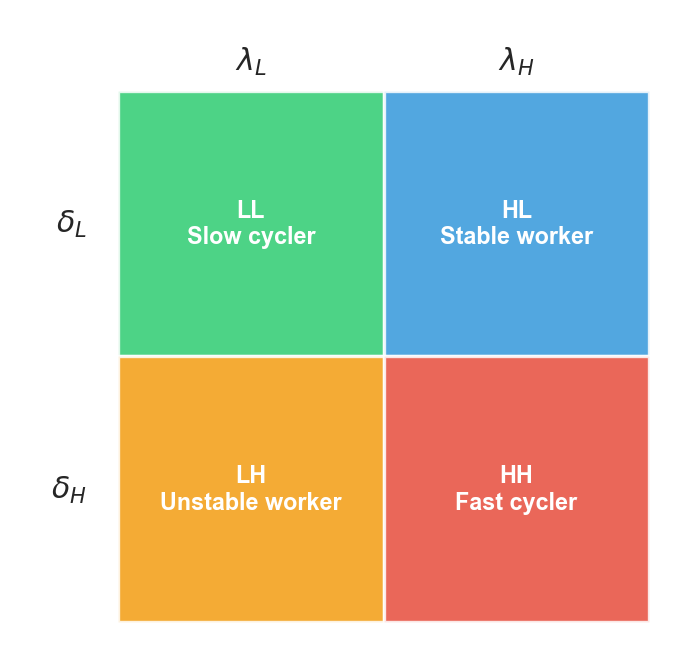

In [19]:
# ---- 2x2 type diagram for slides (clean style, plot colors) ----

cell_map = {(0, 1): 3,   # top-left:     LL slow cycler
            (1, 1): 1,   # top-right:    HL stable worker
            (0, 0): 2,   # bottom-left:  LH unstable worker
            (1, 0): 0}   # bottom-right: HH fast cycler

fig, ax = plt.subplots(figsize=(7, 5.5))
for (cx, cy), t in cell_map.items():
    ax.add_patch(plt.Rectangle((cx, cy), 1, 1, facecolor=colors_4[t],
                               alpha=0.85, edgecolor='white', linewidth=2))
    ax.text(cx + 0.5, cy + 0.5,
            f'{TYPE_LABELS[t]}\n{TYPE_NAMES[t]}',
            ha='center', va='center', fontsize=14, color='white',
            fontweight='bold')

# axis labels like the sketch
ax.text(0.5, 2.08, r'$\lambda_L$', ha='center', fontsize=18)
ax.text(1.5, 2.08, r'$\lambda_H$', ha='center', fontsize=18)
ax.text(-0.12, 1.5, r'$\delta_L$', va='center', ha='right', fontsize=18)
ax.text(-0.12, 0.5, r'$\delta_H$', va='center', ha='right', fontsize=18)

ax.set_xlim(-0.4, 2.05)
ax.set_ylim(-0.05, 2.3)
ax.set_aspect('equal')
ax.axis('off')
ax.grid(False)

fig.tight_layout()
fig.savefig('./output/sample_selection/type_grid_2x2.png',
            bbox_inches='tight', dpi=150, transparent=True)
plt.show()

In [20]:
# ---- Implied moments of the discrete distribution ----

share_lam_H = pi_HH + pi_HL
share_lam_L = pi_LH + pi_LL
share_del_H = pi_HH + pi_LH
share_del_L = pi_HL + pi_LL

E_lam = share_lam_H * lam_H + share_lam_L * lam_L
E_del = share_del_H * delta_H + share_del_L * delta_L

E_lam2 = share_lam_H * lam_H**2 + share_lam_L * lam_L**2
E_del2 = share_del_H * delta_H**2 + share_del_L * delta_L**2
Var_lam = E_lam2 - E_lam**2
Var_del = E_del2 - E_del**2

E_lam_del = (pi_HH * lam_H * delta_H + pi_HL * lam_H * delta_L +
             pi_LH * lam_L * delta_H + pi_LL * lam_L * delta_L)
Cov_lam_del = E_lam_del - E_lam * E_del
Corr_lam_del = Cov_lam_del / np.sqrt(Var_lam * Var_del) if Var_lam > 0 and Var_del > 0 else 0

E_inv_lam = share_lam_H / lam_H + share_lam_L / lam_L
E_inv_del = share_del_H / delta_H + share_del_L / delta_L

print('Implied distribution moments:')
print(f'  E[lambda]      = {E_lam:.5f}   (data MLE: {lambda_hat:.5f})')
print(f'  E[delta]       = {E_del:.5f}   (data MLE: {delta_hat:.5f})')
print(f'  SD(lambda)     = {np.sqrt(Var_lam):.5f}')
print(f'  SD(delta)      = {np.sqrt(Var_del):.5f}')
print(f'  Corr(lam,del)  = {Corr_lam_del:.4f}')
print(f'    (cf. lognormal estimate: rho = -0.034)')
print()
print('Implied mean spell durations:')
print(f'  E[1/lambda] = {E_inv_lam:.1f} months  ({E_inv_lam*30:.0f} days)')
print(f'  E[1/delta]  = {E_inv_del:.1f} months  ({E_inv_del*30:.0f} days)')
print()
print('Off-diagonal mass (stable + unstable types):')
print(f'  pi_HL + pi_LH = {pi_HL + pi_LH:.4f}  (negative-correlation types)')
print(f'  pi_HH + pi_LL = {pi_HH + pi_LL:.4f}  (positive-correlation types)')

Implied distribution moments:
  E[lambda]      = 0.02107   (data MLE: 0.01743)
  E[delta]       = 0.01528   (data MLE: 0.00813)
  SD(lambda)     = 0.00954
  SD(delta)      = 0.01830
  Corr(lam,del)  = -0.6205
    (cf. lognormal estimate: rho = -0.034)

Implied mean spell durations:
  E[1/lambda] = 159.8 months  (4794 days)
  E[1/delta]  = 303.4 months  (9103 days)

Off-diagonal mass (stable + unstable types):
  pi_HL + pi_LH = 0.8317  (negative-correlation types)
  pi_HH + pi_LL = 0.1683  (positive-correlation types)


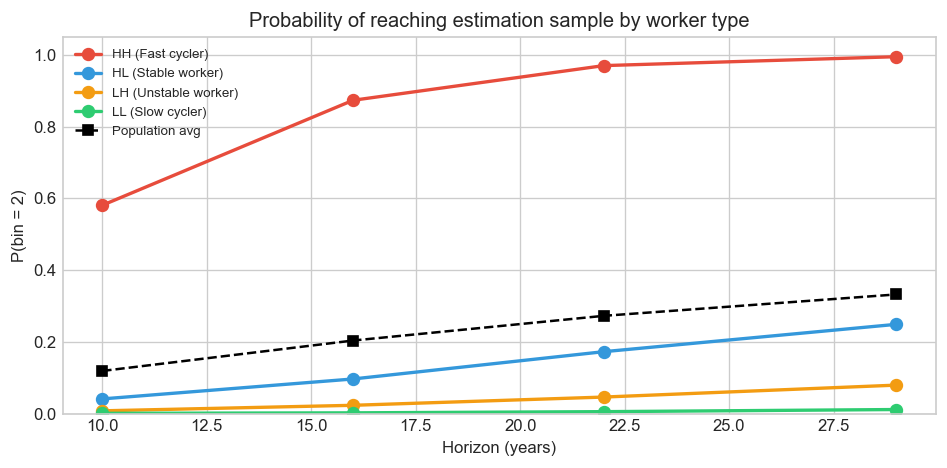

In [21]:
# ---- Selection into sample (bin 2) by type ----

fig, ax = plt.subplots(figsize=(8, 4))

for t, (lam, delta) in enumerate(type_rates):
    p2_by_T = [bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])[4] for i,Ti in enumerate(HORIZONS)]
    ax.plot([Ti//12 for Ti in HORIZONS], p2_by_T, 'o-', color=colors_4[t],
            label=f'{TYPE_LABELS[t]} ({TYPE_NAMES[t]})', lw=2, markersize=7)

pop_p2 = [best_moms[i, 4] for i in range(len(HORIZONS))]
ax.plot([Ti//12 for Ti in HORIZONS], pop_p2, 'ks--', label='Population avg',
        lw=1.5, markersize=6)

ax.set_xlabel('Horizon (years)')
ax.set_ylabel('P(bin = 2)')
ax.set_title('Probability of reaching estimation sample by worker type')
ax.legend(fontsize=8)
ax.set_ylim(0, 1.05)
fig.tight_layout()
# fig.savefig('./output/sample_selection/selection_by_type.png', bbox_inches='tight')
plt.show()

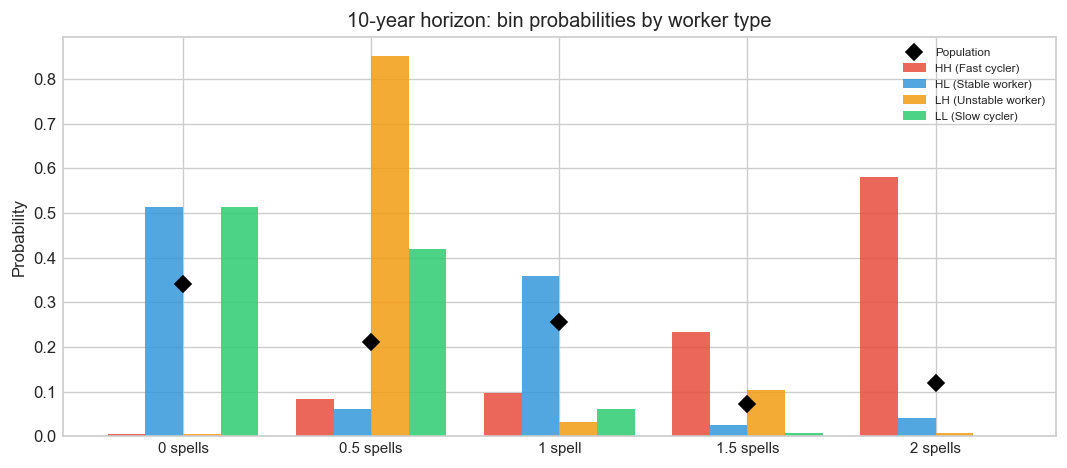

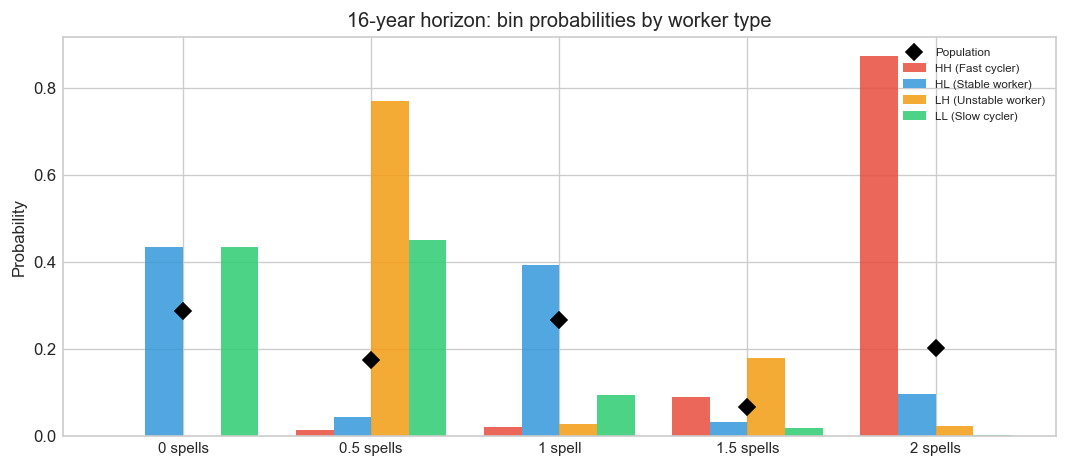

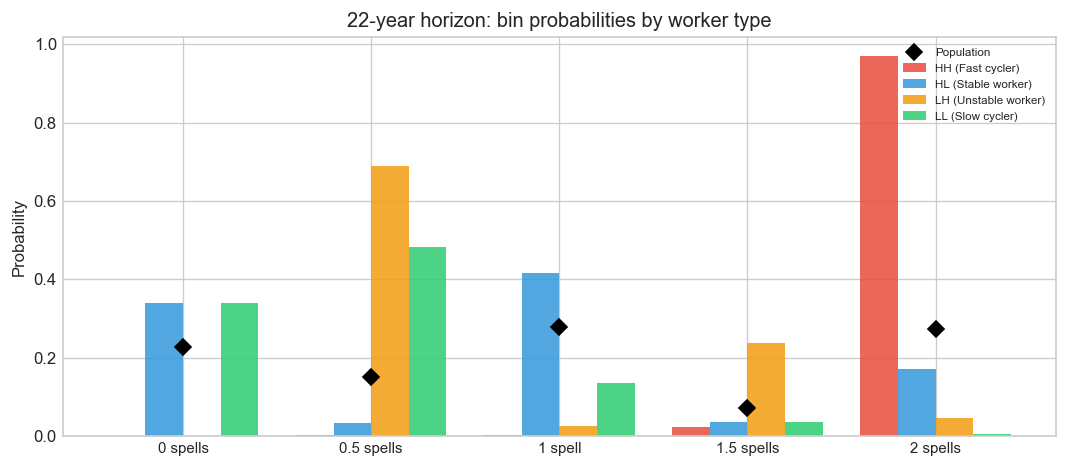

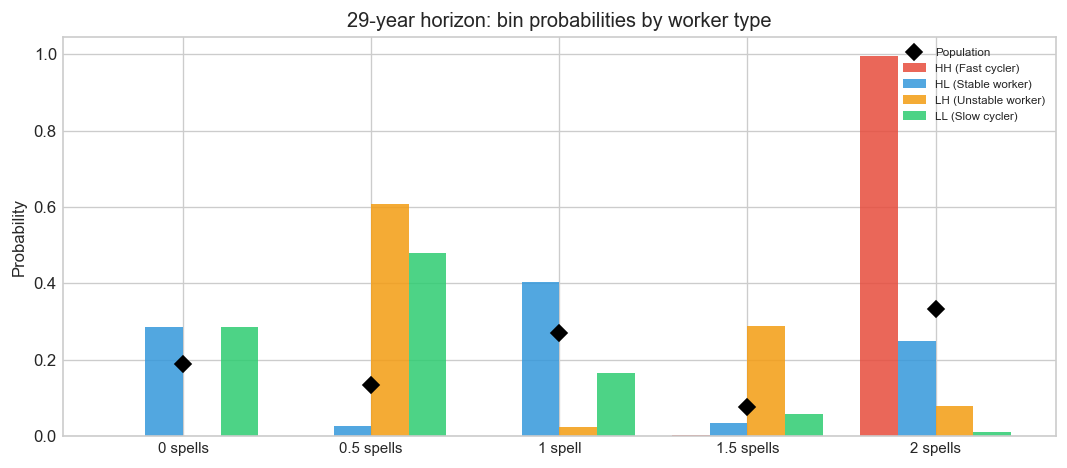

In [22]:
# ---- Paper figures: bin probabilities by type at each horizon ----

BIN_NAMES = ['0 spells', '0.5 spells', '1 spell', '1.5 spells', '2 spells']
i=0
for Ti, year in zip(HORIZONS, YEARS):
    per_type = np.zeros((4, 5))
    for t, (lam, delta) in enumerate(type_rates):
        per_type[t] = bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])

    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(5)
    n_types = 4
    total_w = 0.8
    w = total_w / n_types

    for t in range(n_types):
        offset = (t - n_types/2 + 0.5) * w
        ax.bar(x + offset, per_type[t], w,
               label=f'{TYPE_LABELS[t]} ({TYPE_NAMES[t]})',
               color=colors_4[t], alpha=0.85)
    i+=1
    # Population average as diamonds
    pop_bins = sum(type_shares_list[t] * per_type[t] for t in range(4))
    ax.plot(x, pop_bins, 'kD', markersize=7, label='Population', zorder=5)

    ax.set_xticks(x)
    ax.set_xticklabels(BIN_NAMES, fontsize=9)
    ax.set_ylabel('Probability')
    ax.set_title(f'{Ti//12}-year horizon: bin probabilities by worker type')
    ax.legend(fontsize=7, loc='upper right')
    fig.tight_layout()
    # fig.savefig(f'./output/sample_selection/selection_sim_{Ti//12}year.png', bbox_inches='tight')
    plt.show()

In [23]:
print('=' * 65)
print('ESTIMATION SUMMARY -- Discrete 2x2 GMM')
print('=' * 65)

print(f'\nObjective value: {result.fun:.2f}')
print(f'Converged: {result.success}, nfev: {result.nfev}')

print(f'\n--- Hazard rates ---')
print(f'  lambda_H = {lam_H:.5f}  (mean unstable dur = {1/lam_H:.1f} months)')
print(f'  lambda_L = {lam_L:.5f}  (mean unstable dur = {1/lam_L:.1f} months)')
print(f'  delta_H  = {delta_H:.5f}  (mean stable dur   = {1/delta_H:.1f} months)')
print(f'  delta_L  = {delta_L:.5f}  (mean stable dur   = {1/delta_L:.1f} months)')

print(f'\n--- Type shares ---')
for lab, nm, sh in zip(TYPE_LABELS, TYPE_NAMES, [pi_HH, pi_HL, pi_LH, pi_LL]):
    print(f'  {lab}  {sh:7.4f}  {nm}')

print(f'\n--- Implied moments ---')
print(f'  E[lambda]     = {E_lam:.5f}  (data: {lambda_hat:.5f})')
print(f'  E[delta]      = {E_del:.5f}  (data: {delta_hat:.5f})')
print(f'  Corr(lam,del) = {Corr_lam_del:.4f}')
print(f'  E[unstable spell dur] = {E_inv_lam:.1f} months')
print(f'  E[stable spell dur]   = {E_inv_del:.1f} months')

print(f'\n--- Interpretation ---')
if pi_HL + pi_LH > pi_HH + pi_LL:
    print(f'  Off-diagonal types dominate ({pi_HL+pi_LH:.1%} vs {pi_HH+pi_LL:.1%})')
    print(f'  -> Supports "stable vs unstable" worker types (negative correlation)')
else:
    print(f'  Diagonal types dominate ({pi_HH+pi_LL:.1%} vs {pi_HL+pi_LH:.1%})')
    print(f'  -> Supports "fast vs slow" worker types (positive correlation)')

ESTIMATION SUMMARY -- Discrete 2x2 GMM

Objective value: 5988.33
Converged: True, nfev: 56199

--- Hazard rates ---
  lambda_H = 0.02573  (mean unstable dur = 38.9 months)
  lambda_L = 0.00150  (mean unstable dur = 668.6 months)
  delta_H  = 0.04098  (mean stable dur   = 24.4 months)
  delta_L  = 0.00225  (mean stable dur   = 444.9 months)

--- Type shares ---
  HH   0.1564  Fast cycler
  HL   0.6516  Stable worker
  LH   0.1801  Unstable worker
  LL   0.0119  Slow cycler

--- Implied moments ---
  E[lambda]     = 0.02107  (data: 0.01743)
  E[delta]      = 0.01528  (data: 0.00813)
  Corr(lam,del) = -0.6205
  E[unstable spell dur] = 159.8 months
  E[stable spell dur]   = 303.4 months

--- Interpretation ---
  Off-diagonal types dominate (83.2% vs 16.8%)
  -> Supports "stable vs unstable" worker types (negative correlation)


## Simulation

In [25]:
from scipy.stats import expon

In [26]:
def variance_decomp(df):
    data_ht = df.copy()
    Ns = df.size
    data_ht['mu_i'] = (data_ht.n1 + data_ht.n2)/2
    data_ht['mu_y'] = np.sum((data_ht.n1 + data_ht.n2))/(2*Ns)
    
    data_ht['sig_i'] = (data_ht.n1 - data_ht.n2)**2/2
    data_ht['sig_y'] = np.sum((data_ht.n1**2 + data_ht.n2**2 - 2*data_ht.mu_y**2))/(2*Ns-1)
    
    data_ht['sig_w'] = np.sum(data_ht.sig_i)/Ns
    data_ht['sig_b'] = np.sum(data_ht.mu_i**2 - 0.5*data_ht.sig_i)/Ns - data_ht.mu_y**2 + (1/(2*Ns))*data_ht.sig_y
    
    data_ht['sig_c'] = np.sum(data_ht.mu_i**2 - 0.5*data_ht.sig_i)/Ns
    data_ht['sig_e'] = np.sum(1.5*data_ht.sig_i - data_ht.mu_i**2)/Ns
    return data_ht

In [27]:
type_rates = [(lam_H, delta_H), (lam_H, delta_L),
              (lam_L, delta_H), (lam_L, delta_L)]
type_shares_list = [pi_HH, pi_HL, pi_LH, pi_LL]
i=0
composition_dic = {}
for Ti, year in zip(HORIZONS, YEARS):
    per_type = np.zeros((4, 5))
    for t, (lam, delta) in enumerate(type_rates):
        per_type[t] = bin_probs_single(lam, delta, Ti, P_START_U_VEC[i])

    pop_bins = np.zeros(5)
    for t in range(4):
        pop_bins += type_shares_list[t] * per_type[t]

    # P(type | bin) via Bayes
    composition = np.zeros((4, 5))
    for t in range(4):
        for b in range(5):
            if pop_bins[b] > 1e-12:
                composition[t, b] = type_shares_list[t] * per_type[t, b] / pop_bins[b]
    composition_dic[year] = composition
    i+=1

In [28]:
Ns = 100000

decomp_sim = {}
for year in YEARS:
    share_high = int(np.sum(composition_dic[year][:2,-1])*Ns)
    
    sample_fast = expon.rvs(scale=1/lam_H, size=(share_high,2))
    sample_slow = expon.rvs(scale=1/lam_L, size=(Ns-share_high,2))
    
    sample_ht = np.vstack((sample_fast,sample_slow))
    
    data_ht = pd.DataFrame(sample_ht, columns=['n1','n2'])
    decomp_sim[year] = variance_decomp(data_ht)

    print('Year {}'.format(year))
    print('Share high lambda in the 2+ spell bin: {:,.2f}'.format(np.sum(composition_dic[year][:2,-1])))
    print('Share duration dependence:  {:,.4f}'.format(decomp_sim[year].sig_e.iloc[0]/decomp_sim[year].sig_y.iloc[0]))
    print('Share heterogeneity:  {:,.4f} \n'.format(decomp_sim[year].sig_b.iloc[0]/decomp_sim[year].sig_y.iloc[0]))

# data_ht.head()

Year 2011
Share high lambda in the 2+ spell bin: 0.99
Share duration dependence:  0.0502
Share heterogeneity:  0.4101 

Year 2005
Share high lambda in the 2+ spell bin: 0.98
Share duration dependence:  -0.0223
Share heterogeneity:  0.4613 

Year 1999
Share high lambda in the 2+ spell bin: 0.97
Share duration dependence:  0.0086
Share heterogeneity:  0.4532 

Year 1992
Share high lambda in the 2+ spell bin: 0.96
Share duration dependence:  -0.0148
Share heterogeneity:  0.4656 



In [30]:
# ============================================================================
# Export computed quantities -> output/sample_selection/selection_<country>.json
# (consumed by sample_selection_tables.py to build output/tables/sample_selection_tables.tex)
# ============================================================================
import json as _json

_COUNTRY = "Germany" if 2014 in YEARS else "Spain"
_TYPES = ['HH', 'HL', 'LH', 'LL']

def _group_dict(comp, share):
    return {**{t: float(comp[k]) for k, t in enumerate(_TYPES)},
            "Elam": float((comp * lam_vals).sum()),
            "Edel": float((comp * del_vals).sum()),
            "share": float(share)}

_windows_out = []
for _i, (_Ti, _yr) in enumerate(zip(HORIZONS, YEARS)):
    cp, c1, c2, p1, p2 = _collapsed_compositions(_Ti, P_START_U_VEC[_i])
    _windows_out.append({
        "horizon": int(round(_Ti / 12)), "year": int(_yr),
        "population": _group_dict(cp, 1.0),
        "one_spell":  _group_dict(c1, p1),
        "two_spell":  _group_dict(c2, p2),
        "ratio": {t: float(c2[k] / cp[k]) if cp[k] > 0 else 0.0
                  for k, t in enumerate(_TYPES)},
    })

_dd_out = [{"horizon": int(round(HORIZONS[_i] / 12)),
            "fast_cycler_share": float(np.sum(composition_dic[_yr][:2, -1])),
            "dd_share": float(decomp_sim[_yr].sig_e.iloc[0] / decomp_sim[_yr].sig_y.iloc[0]),
            "het_share": float(decomp_sim[_yr].sig_b.iloc[0] / decomp_sim[_yr].sig_y.iloc[0])}
           for _i, _yr in enumerate(YEARS)]

_params = {"lam_H": float(lam_H), "lam_L": float(lam_L),
           "delta_H": float(delta_H), "delta_L": float(delta_L),
           "pi_HH": float(pi_HH), "pi_HL": float(pi_HL),
           "pi_LH": float(pi_LH), "pi_LL": float(pi_LL)}

_bins_out = [{"horizon": int(round(HORIZONS[_i] / 12)), "year": int(_yr),
              "shares": [float(x) for x in data_shares[_i]],
              "N": int(round(float(data_N[_i])))}
             for _i, _yr in enumerate(YEARS)]

os.makedirs("sample_selection", exist_ok=True)
with open("output/sample_selection/selection_{}.json".format(_COUNTRY.lower()), "w") as _f:
    _json.dump({"country": _COUNTRY, "end_year": int(END_YEAR),
                "params": _params, "bin_shares": _bins_out,
                "windows": _windows_out, "dd": _dd_out}, _f, indent=2)
print("Wrote output/sample_selection/selection_{}.json".format(_COUNTRY.lower()))

Wrote output/sample_selection/selection_spain.json
